# Hyperspectral Mapping for Invasive Mesquite Detection and Regrowth Monitoring​

**Arab Youth Space Hackathon — 813 Challenge · Theme 02: Precision Agriculture & Crop Intelligence**  
Ras Al Khaimah, UAE · EnMAP Level-2A · 7 January 2024

## 1. Purpose and scope
This project explores how hyperspectral imagery can support future research into invasive Mesquite (*Prosopis juliflora*) in the UAE. Following limitations in the Tanager data available to the team, EnMAP imagery was used to develop an initial workflow for the Ras Al Khaimah study area.

The notebook generates true-colour and colour-infrared maps, calculates NDVI and NDRE, and presents exploratory spectral comparisons. These outputs support vegetation inspection and planning for future fieldwork. Species-level identification of Mesquite and its distinction from native Ghaf remain objectives for further research.

**Computed outputs:** Image composites, vegetation indices and the study-area map are generated from the supplied EnMAP raster. Numerical sample checks refer to the earlier records stored in the GeoPackage.

**Previously exported figures:** The four-sample map and spectral graph from EnMAP-Box are displayed as saved images with presentation labels and a colour legend. Their final numerical spectra and coordinates are unavailable in the supplied GeoPackage, which contains four earlier records representing three unique locations.

**Execution and reproducibility:** The updated Section 8 display cells have been run successfully in Google Colab. A complete restart-and-run-all check of the revised notebook remains to be completed. Rerunning requires the original input files and the two exported PNG images; the public code package alone does not contain all required inputs.


### Note for reviewers

This notebook includes saved figures and outputs for inspection. **You do not need to run the code or upload files to view the saved results.** A “Saved results for review” gallery is also provided at the end.

To recalculate the analysis, the original EnMAP input files are required. Selecting “Run all” may therefore prompt you to upload data.

The four-sample figure uses previously exported EnMAP-Box images. It is presented for visual comparison; the final four samples have not been numerically verified against the supplied GeoPackage. This project is an exploratory prototype for future Mesquite research, not a validated species-detection or regrowth-monitoring system.

## 2. Data and provenance
The supplied GeoTIFF is a QGIS clip of EnMAP datatake 56678, tile 013, acquired on
2024-01-07 at 07:30:53.422051 UTC. Metadata describes Level-2A **land-mode surface reflectance**,
processor version 01.05.02 and processing on 2026-01-29. Acquisition and processing dates are different.
The clip has 238 columns × 261 rows with a 30 m grid in WGS84 / UTM zone 40N (EPSG:32640).
The XML's larger image dimensions refer to the full source tile, not this clip.

The organizers' Planet Tanager tutorial informed the sequence of exploration, composites and indices.
This implementation is newly written for the actual GeoTIFF/XML/GeoPackage. It contains no Tanager
HDF5 paths, Planet download dependencies or inherited Planet data-licence claims.

Image composites and vegetation indices are calculated from the supplied EnMAP raster using its metadata. Section 8 additionally displays previously exported sample-location and spectral images from EnMAP-Box. These images document the final visual selections, while the supplied GeoPackage preserves an earlier sample set.


## 3. Environment setup
The original workflow was tested locally using Python 3.12, NumPy 2.3.5 and Matplotlib 3.10.8. The revised Section 8 display cells have also run successfully in Google Colab. A complete restart-and-run-all check of the revised notebook remains to be completed.

The TIFF is uncompressed and its structure is simple. A strict, small reader avoids GDAL/rasterio
binary-installation requirements. SQLite reads the GeoPackage; a WGS84 UTM series projects its points.
Readers reject unsupported formats. This implementation is scoped to the supplied files, not a general GIS library.

Install from the repository with `python -m pip install -r requirements.txt`. In a fresh Colab runtime,
the following cell installs mismatched dependencies before any numerical imports. Restart the runtime
if numerical packages were already imported. Local validation used an offline wheelhouse reconstructed
from the runtime's installed distributions because PyPI access was blocked; a public PyPI install is unverified.


In [44]:
import sys, subprocess, importlib.metadata as metadata
REQUIREMENTS = ['numpy==2.3.5', 'matplotlib==3.10.8', 'contourpy==1.3.3', 'cycler==0.12.1', 'fonttools==4.61.1', 'kiwisolver==1.4.9', 'packaging==26.3', 'pillow==12.3.0', 'pyparsing==3.3.2', 'python-dateutil==2.9.0.post0', 'six==1.17.0']
mismatched=[]
for requirement in REQUIREMENTS:
    name,version=requirement.split('==')
    try: installed=metadata.version(name)
    except metadata.PackageNotFoundError: installed=None
    if installed!=version: mismatched.append(requirement)
if mismatched:
    subprocess.check_call([sys.executable,'-m','pip','install',*REQUIREMENTS])
print('Python:', sys.version.split()[0])
print('Pinned dependencies verified:', len(REQUIREMENTS))


Python: 3.13.16
Pinned dependencies verified: 11


In [50]:
from pathlib import Path

source = Path("metadata.xml.XML")
target = Path("metadata.xml")

if source.exists() and not target.exists():
    source.rename(target)

print("Metadata file found:", target.exists())

Metadata file found: True


## 4. Locate and validate included data
This step locates the EnMAP raster ZIP, metadata.xml and spectral-profile GeoPackage. In the current Colab workflow, these files are uploaded manually when they are not already available. Filenames must match those expected by the code.

This cell identifies the three original input files by their SHA-256 checksums, verifies them, and extracts the satellite raster.

The two PNG images used in Section 8 are uploaded separately.


In [54]:
from pathlib import Path
import os, json, zipfile, hashlib, csv, warnings, shutil
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

ROOT = Path("/content")
DATA = ROOT / "enmap_inputs"
OUT = ROOT / "outputs"
cache = ROOT / "enmap_cache"

for folder in (DATA, OUT, cache):
    folder.mkdir(parents=True, exist_ok=True)

# Checksums of the original files supplied for this project.
expected = {
    "RAK_20240107_EnMAP_Data.zip":
        "f7d9e5a8aa72858a3030b8575af5b438fe4c52bdbe5c0a41f4ab6f4b592337e0",
    "metadata.xml":
        "2a5e8cf5f6e9113396fffc6eedce8bfb3c3af50509c8dbc3844c3a862232d9db",
    "RAK_20240107_Spectral_Profiles.gpkg":
        "5b60b8873866cc9d06d8c927eb0fa8ff29e92d452b4d2c7160d534011c15be71",
}

# Search uploaded files and previously prepared inputs.
candidates = [
    p for folder in (ROOT, DATA)
    for p in folder.iterdir()
    if p.is_file() and p.suffix.lower() in (".zip", ".xml", ".gpkg")
]

matched = {}
for path in candidates:
    with path.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    for name, wanted in expected.items():
        if digest == wanted:
            matched[name] = path

missing = [name for name in expected if name not in matched]
if missing:
    raise FileNotFoundError(
        "These original files are missing or do not match:\n"
        + "\n".join(missing)
        + "\nUpload only these files using Colab's Files panel, "
          "then rerun this cell."
    )

for name, source in matched.items():
    destination = DATA / name
    if source.resolve() != destination.resolve():
        shutil.copy2(source, destination)
    print("Verified:", name)

raster_name = "RAK_20240107_EnMAP_L2A_clip.tif"
RASTER = cache / raster_name

with zipfile.ZipFile(DATA / "RAK_20240107_EnMAP_Data.zip") as archive:
    if archive.namelist() != [raster_name]:
        raise ValueError("Unexpected contents in the raster ZIP.")
    with archive.open(raster_name) as source, RASTER.open("wb") as target:
        shutil.copyfileobj(source, target)

print("Section 4 complete. Original inputs verified.")
print("Continue with the next code cell.")

Verified: RAK_20240107_Spectral_Profiles.gpkg
Verified: RAK_20240107_EnMAP_Data.zip
Verified: metadata.xml
Section 4 complete. Original inputs verified.
Continue with the next code cell.


In [57]:
"""Small, fail-closed readers for this inspected GeoTIFF and point GeoPackage.
No GDAL installation required. Not a general replacement for rasterio/pyproj.
Supports classic uncompressed, pixel-interleaved, north-up Int16 GeoTIFF only.
"""
from pathlib import Path
import struct, sqlite3, json, math
import numpy as np

def read_geotiff(path):
    with open(path,'rb') as f:
        h=f.read(8)
        if h[:2] not in (b'II',b'MM'): raise ValueError('Not TIFF')
        endian='<' if h[:2]==b'II' else '>'
        magic,offset=struct.unpack(endian+'HI',h[2:])
        if magic!=42: raise ValueError('Only classic TIFF supported')
        f.seek(offset);n=struct.unpack(endian+'H',f.read(2))[0]
        entries=[struct.unpack(endian+'HHI4s',f.read(12)) for _ in range(n)]
        if struct.unpack(endian+'I',f.read(4))[0]!=0:raise ValueError('Multiple IFDs unsupported')
        tags={};formats={1:'B',2:'s',3:'H',4:'I',12:'d'}
        for key,typ,count,value in entries:
            if typ not in formats: raise ValueError(f'Unsupported tag type {typ}')
            fmt=formats[typ];size=(1 if typ==2 else struct.calcsize(fmt))*count
            if size>4:f.seek(struct.unpack(endian+'I',value)[0]);value=f.read(size)
            if len(value)<size:raise ValueError('Truncated tag')
            tags[key]=value[:size].rstrip(b'\0').decode() if typ==2 else struct.unpack(endian+str(count)+fmt,value[:size])
        one=lambda k,default=None:tags.get(k,(default,))[0]
        w,h,b=one(256),one(257),one(277)
        if one(259)!=1 or one(284,1)!=1 or set(tags[258])!={16} or set(tags[339])!={2}:
            raise ValueError('Expected uncompressed contiguous Int16 TIFF')
        if 34264 in tags or one(274,1)!=1:raise ValueError('Rotation or orientation unsupported')
        offsets,counts=tags[273],tags[279];rows=one(278)
        if len(offsets)!=math.ceil(h/rows):raise ValueError('Unexpected strip layout')
        chunks=[]
        for k,(off,length) in enumerate(zip(offsets,counts)):
            expected=min(rows,h-k*rows)*w*b*2
            if length!=expected:raise ValueError('Strip size mismatch')
            f.seek(off);raw=f.read(length)
            if len(raw)!=length:raise ValueError('Truncated strip')
            chunks.append(raw)
        cube=np.frombuffer(b''.join(chunks),dtype=endian+'i2').reshape(h,w,b).transpose(2,0,1).copy()
        keys=tags[34735];geo={keys[i]:(keys[i+1],keys[i+2],keys[i+3]) for i in range(4,len(keys),4)}
        if geo[3072]!=(0,1,32640) or geo[1025]!=(0,1,1):raise ValueError('Expected EPSG:32640 PixelIsArea')
        sx,sy,_=tags[33550];i,j,k,x,y,z=tags[33922]
        if sx<=0 or sy<=0:raise ValueError('Invalid resolution')
        left=x-i*sx;top=y+j*sy
        meta={'width':w,'height':h,'bands':b,'dtype':str(cube.dtype),'crs':'EPSG:32640','resolution_m':[sx,sy],
              'bounds':[left,top-h*sy,left+w*sx,top],'nodata':int(tags[42113]),'raster_type':'PixelIsArea',
              'compression':'none','orientation':'north-up','scaling_in_tiff':False}
        return cube,meta

def lonlat_to_utm40(lon,lat):
    """WGS84 Transverse Mercator series, zone 40N; limited to this UAE AOI.
    Snyder USGS PP1395 equations 8-9..8-15. Return easting/northing metres.
    """
    if not (54<=lon<=60 and 0<=lat<84):raise ValueError('Outside supported zone 40N')
    a=6378137.;f=1/298.257223563;e2=f*(2-f);ep=e2/(1-e2);k=.9996
    p=math.radians(lat);dl=math.radians(lon-57);s=math.sin(p);c=math.cos(p);t=math.tan(p)
    N=a/math.sqrt(1-e2*s*s);T=t*t;C=ep*c*c;A=c*dl
    M=a*((1-e2/4-3*e2**2/64-5*e2**3/256)*p-(3*e2/8+3*e2**2/32+45*e2**3/1024)*math.sin(2*p)
         +(15*e2**2/256+45*e2**3/1024)*math.sin(4*p)-35*e2**3/3072*math.sin(6*p))
    x=500000+k*N*(A+(1-T+C)*A**3/6+(5-18*T+T*T+72*C-58*ep)*A**5/120)
    y=k*(M+N*t*(A*A/2+(5-T+9*C+4*C*C)*A**4/24+(61-58*T+T*T+600*C-330*ep)*A**6/720))
    return x,y

def read_samples(path):
    with sqlite3.connect(f'file:{Path(path).resolve()}?mode=ro',uri=True) as con:
        tables=con.execute('SELECT table_name,column_name,geometry_type_name,srs_id,z,m FROM gpkg_geometry_columns').fetchall()
        if len(tables)!=1:raise ValueError('Expected one point layer')
        table,geom,kind,srs,z,m=tables[0]
        if (kind,srs,z,m)!=('POINT',4326,0,0):raise ValueError('Expected 2D WGS84 points')
        quote=lambda s:'"'+s.replace('"','""')+'"'
        records=con.execute(f'SELECT fid,name,{quote(geom)},profiles FROM {quote(table)} ORDER BY fid').fetchall()
        result=[]
        for fid,name,blob,pr in records:
            if blob[:2]!=b'GP':raise ValueError('Invalid GeoPackage geometry')
            flags=blob[3];order='<' if flags&1 else '>';srs_geom=struct.unpack(order+'i',blob[4:8])[0]
            env=(flags>>1)&7;length={0:0,1:32,2:48,3:48,4:64}.get(env)
            if length is None or flags&16 or srs_geom!=4326:raise ValueError('Unsupported point geometry')
            wkb=blob[8+length:];order='<' if wkb[0]==1 else '>'
            if struct.unpack(order+'I',wkb[1:5])[0]!=1:raise ValueError('Not 2D POINT')
            lon,lat=struct.unpack(order+'dd',wkb[5:21]);profile=json.loads(pr)
            if set(profile)!={'y'}:raise ValueError('Unexpected profile schema')
            result.append({'fid':fid,'name':name,'longitude':lon,'latitude':lat,'stored':np.array(profile['y'],dtype=float)})
        return result,{'layer':table,'crs':'EPSG:4326','geometry':kind,'fields':['fid','geom','name','profiles'],
                       'profile_schema':'JSON object with y array only; no wavelength or colour fields','record_count':len(result)}

def pixel_at(meta,x,y):
    left,bottom,right,top=meta['bounds'];sx,sy=meta['resolution_m']
    col=math.floor((x-left)/sx);row=math.floor((top-y)/sy)
    if not (0<=row<meta['height'] and 0<=col<meta['width']):raise ValueError('Point outside clip')
    return row,col


## 5. Raster and spectral quality audit
Apply each band's XML gain and offset **once**, after masking TIFF nodata (`-32768`). No wavelength
spacing or scale is inferred from sample values. All 224 ordered XML bands are retained in the audit.
Stored GeoPackage profiles contain only a `y` array; a full-band numerical match to the source raster
provides a direct check of their band ordering.

A pixel can be valid for NDVI while missing in another band. Therefore, no all-224-band intersection
mask is used. Numeric validity is **not cloud clearance**: the supplied ZIP has no per-pixel quality layers.
The parent XML reports 9% cloud cover, no cirrus/haze removal, and a TEMPERATURE screening warning.
Those parent-scene facts do not establish cloud cover or sensor error within this clip.

GeoPackage-to-raster profile checks apply only to the earlier saved samples; they do not validate the four selections displayed in the exported PNG figures.


In [58]:
cube,raster_info=read_geotiff(RASTER)
xml=ET.parse(DATA/'metadata.xml').getroot()
band_nodes=xml.findall('specific/bandCharacterisation/bandID')
assert [int(b.attrib['number']) for b in band_nodes]==list(range(1,cube.shape[0]+1))
wavelengths=np.array([float(b.findtext('wavelengthCenterOfBand')) for b in band_nodes])
gain=np.array([float(b.findtext('GainOfBand')) for b in band_nodes])
offset=np.array([float(b.findtext('OffsetOfBand')) for b in band_nodes])
fwhm=np.array([float(b.findtext('FWHMOfBand')) for b in band_nodes])
assert xml.findtext('base/level')=='L2A' and len(wavelengths)==224
assert np.all(np.diff(wavelengths)>0)
valid_band=cube!=raster_info['nodata']
reflectance=cube.astype(float)*gain[:,None,None]+offset[:,None,None]
reflectance[~valid_band]=np.nan
nodata_bands=np.flatnonzero(~valid_band.any(axis=(1,2)))+1
acquisition=xml.findtext('base/temporalCoverage/startTime')
source_citation=xml.findtext('metadata/citation')
# Conservative plotting exclusions; an analyst choice, not an official bad-band list.
plot_excluded=((wavelengths>=900)&(wavelengths<=1000)) | ((wavelengths>=1340)&(wavelengths<=1460)) | ((wavelengths>=1780)&(wavelengths<=2000))
plot_excluded |= ~valid_band.any(axis=(1,2))
qa={**raster_info,'acquisition_utc':acquisition,'wavelength_range_nm':[float(wavelengths.min()),float(wavelengths.max())],
    'gain_unique':np.unique(gain).tolist(),'offset_unique':np.unique(offset).tolist(),
    'all_nodata_bands':nodata_bands.tolist(),'any_band_valid_pixels':int(valid_band.any(axis=0).sum()),
    'all_band_valid_pixels':int(valid_band.all(axis=0).sum()),'total_pixels':int(cube.shape[1]*cube.shape[2]),
    'negative_valid_observations':int(((cube<0)&valid_band).sum()),'reflectance_above_one':int((reflectance>1).sum()),
    'cloud_mask_supplied':False,'parent_cloud_cover_percent':xml.findtext('specific/qualityFlag/cloudCover'),
    'parent_screening':xml.findtext('specific/productQuality/screeningResult/status'),
    'parent_screening_failed_group':xml.findtext('specific/productQuality/screeningResult/failedGroups')}
print(json.dumps(qa,indent=2));print('Source citation:',source_citation)
(OUT/'raster_qa.json').write_text(json.dumps(qa,indent=2))
band_rows=[{'band':i+1,'wavelength_nm':wavelengths[i],'fwhm_nm':fwhm[i],'gain':gain[i],'offset':offset[i],
 'valid_pixels':int(valid_band[i].sum()),'excluded_from_profile_plot':bool(plot_excluded[i])} for i in range(224)]
def show_table(rows,columns=None):
    import html
    columns=columns or list(rows[0])
    fmt=lambda v: f'{v:.6f}' if isinstance(v,float) else str(v)
    head=''.join('<th style="text-align:left;padding:6px;border-bottom:2px solid #789">'+html.escape(c)+'</th>' for c in columns)
    body=''.join('<tr>'+''.join('<td style="padding:6px;border-bottom:1px solid #ddd">'+html.escape(fmt(row[c]))+'</td>' for c in columns)+'</tr>' for row in rows)
    table='<table style="border-collapse:collapse;font-size:13px"><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table>'
    if '_display_html' in globals():_display_html(table)
    else:
        try:
            from IPython.display import display,HTML
            display(HTML(table))
        except ImportError:
            print(' | '.join(columns))
            for row in rows: print(' | '.join(fmt(row[c]) for c in columns))

def save_csv(name,rows):
    with (OUT/name).open('w',newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
save_csv('band_audit.csv',band_rows)
for label,band in [('Blue',16),('Green',30),('Red',48),('Red edge',54),('NIR',73)]:
    print(f'{label:9s}: Band {band:2d} = {wavelengths[band-1]:.3f} nm')


{
  "width": 238,
  "height": 261,
  "bands": 224,
  "dtype": "int16",
  "crs": "EPSG:32640",
  "resolution_m": [
    30.0,
    30.0
  ],
  "bounds": [
    393555.0,
    2835075.0,
    400695.0,
    2842905.0
  ],
  "nodata": -32768,
  "raster_type": "PixelIsArea",
  "compression": "none",
  "orientation": "north-up",
  "scaling_in_tiff": false,
  "acquisition_utc": "2024-01-07T07:30:53.422051Z",
  "wavelength_range_nm": [
    418.416,
    2445.3
  ],
  "gain_unique": [
    0.0001
  ],
  "offset_unique": [
    0.0
  ],
  "all_nodata_bands": [
    131,
    132,
    133,
    134,
    135
  ],
  "any_band_valid_pixels": 62118,
  "all_band_valid_pixels": 0,
  "total_pixels": 62118,
  "negative_valid_observations": 3612,
  "reflectance_above_one": 0,
  "cloud_mask_supplied": false,
  "parent_cloud_cover_percent": "9",
  "parent_screening": "WARNING",
  "parent_screening_failed_group": "TEMPERATURE"
}
Source citation: DLR (2026): EnMAP L0 Product 0000056678_13_L0_20240107T200808_010401_20260

## 6. True-colour and colour-infrared imagery
Retain the QGIS definitions: true colour R/G/B = **48/30/16**; CIR = **73/48/30**.
The near-infrared channel is centred at 847.847 nm. Independent 2nd–98th percentile stretches enhance
visual contrast; colours are display products, not calibrated colour measurements. Negative reflectance
values are retained in the raw audit but masked in these composites and the indices.

Figures use north-up orientation, an equal projected aspect ratio and kilometre axes (EPSG:32640).
Vegetation-like areas often look red in CIR. Red pixels do not identify Ghoeif or any other species.


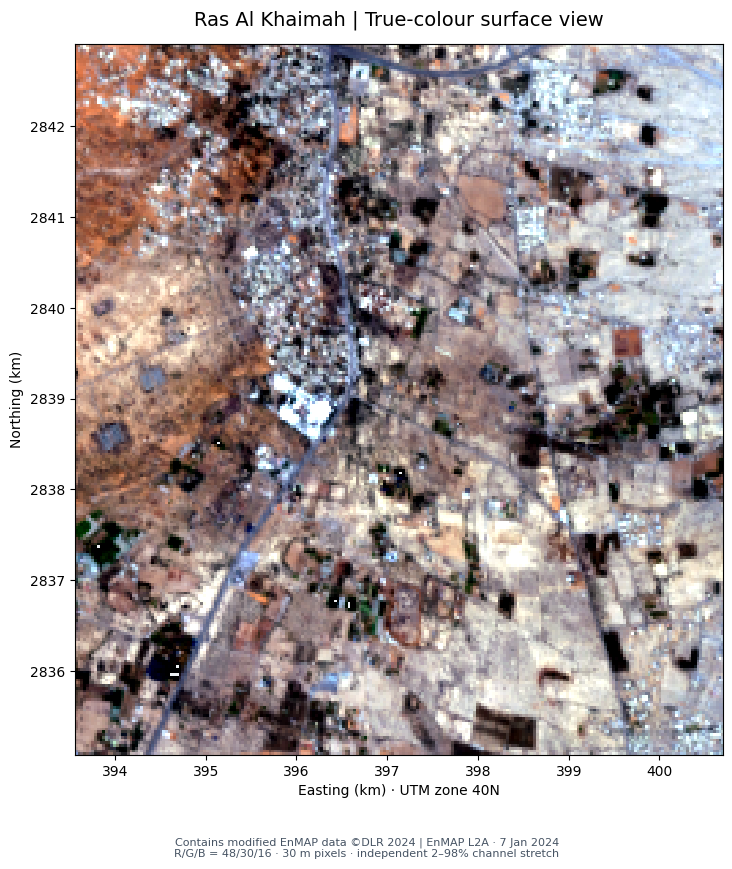

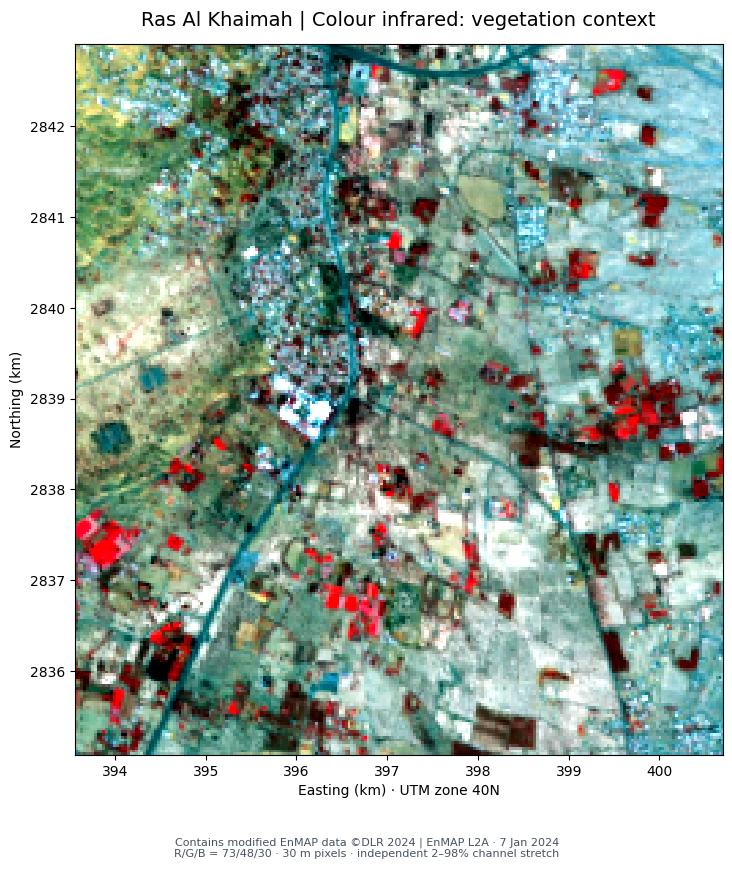

In [59]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':14,'figure.facecolor':'white','savefig.facecolor':'white'})
CREDIT='Contains modified EnMAP data ©DLR 2024 | EnMAP L2A · 7 Jan 2024'
left,bottom,right,top=raster_info['bounds'];extent=np.array([left,right,bottom,top])/1000

def stretched_rgb(bands):
    a=reflectance[np.array(bands)-1].transpose(1,2,0)
    mask=np.isfinite(a).all(axis=2)&(a>=0).all(axis=2)
    rgba=np.zeros((*mask.shape,4),dtype=float)
    for k in range(3):
        lo,hi=np.percentile(a[:,:,k][mask],[2,98])
        if hi<=lo:raise ValueError('No channel dynamic range')
        rgba[:,:,k]=np.clip(np.nan_to_num((a[:,:,k]-lo)/(hi-lo)),0,1)
    rgba[:,:,3]=mask
    return rgba

def map_axis(ax):
    ax.set(xlabel='Easting (km) · UTM zone 40N',ylabel='Northing (km)',aspect='equal')
    ax.ticklabel_format(style='plain',useOffset=False)
    ax.set_facecolor('#eef1f4')

def finish(fig,name,caption):
    fig.text(.5,.018,CREDIT+'\n'+caption,ha='center',va='bottom',fontsize=8,color='#465363')
    fig.tight_layout(rect=[0,.07,1,1]);fig.savefig(OUT/name,dpi=220);plt.show();plt.close(fig)

rgb=stretched_rgb([48,30,16]);cir=stretched_rgb([73,48,30])
for image,title,name,bands in [(rgb,'True-colour surface view','true_color.png','R/G/B = 48/30/16'),(cir,'Colour infrared: vegetation context','color_infrared.png','R/G/B = 73/48/30')]:
    fig,ax=plt.subplots(figsize=(8,8.8));ax.imshow(image,extent=extent,origin='upper',interpolation='nearest')
    map_axis(ax);ax.set_title('Ras Al Khaimah | '+title,pad=14)
    finish(fig,name,bands+' · 30 m pixels · independent 2–98% channel stretch')


## 7. Vegetation indices
\[
NDVI=rac{R_{847.847}-R_{666.637}}{R_{847.847}+R_{666.637}},\qquad
NDRE=rac{R_{847.847}-R_{706.617}}{R_{847.847}+R_{706.617}}
\]
These reproduce QGIS bands 73/48 and 73/54. NDVI describes red–NIR contrast; NDRE uses a red-edge
channel that can respond to canopy/chlorophyll variation. Neither is a direct measurement of nitrogen,
plant health, species identity or crop yield here. No alternate definition is silently substituted.

Use finite, nonnegative input reflectances and a positive denominator above 1e-12. Results outside
[-1,1] are rejected. Statistics are for eligible pixels, not a validated land-cover class. The common
[-1,1] colour scale is fixed across the index maps; it is not a species-classification legend.


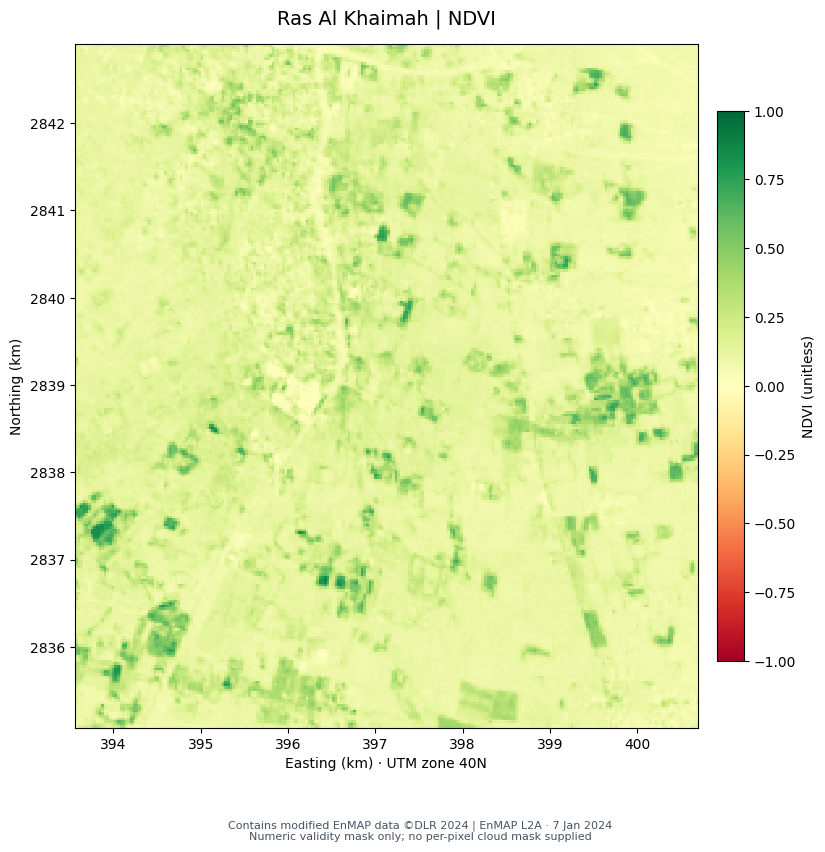

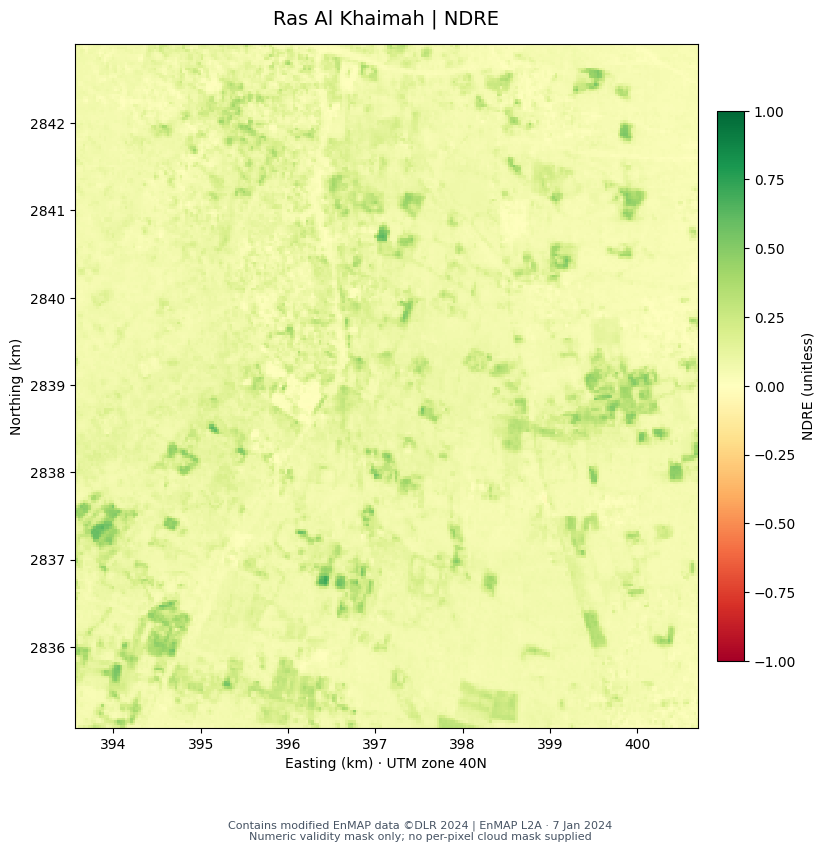

index,valid_pixels,minimum,p05,median,mean,p95,maximum,std
NDVI,62118,-0.037671,0.057872,0.119187,0.150771,0.364549,0.883315,0.101962
NDRE,62118,-0.034452,0.034410,0.078072,0.102482,0.264211,0.717269,0.075987


In [60]:
def normalized_difference(a,b):
    denom=a+b
    valid=np.isfinite(a)&np.isfinite(b)&(a>=0)&(b>=0)&(denom>1e-12)
    result=np.full(a.shape,np.nan,dtype=float)
    np.divide(a-b,denom,out=result,where=valid)
    result[(result < -1)|(result > 1)]=np.nan
    return result
ndvi=normalized_difference(reflectance[72],reflectance[47])
ndre=normalized_difference(reflectance[72],reflectance[53])
index_stats=[]
for name,arr in [('NDVI',ndvi),('NDRE',ndre)]:
    v=arr[np.isfinite(arr)]
    index_stats.append({'index':name,'valid_pixels':int(v.size),'minimum':float(v.min()),'p05':float(np.percentile(v,5)),
        'median':float(np.median(v)),'mean':float(v.mean()),'p95':float(np.percentile(v,95)),'maximum':float(v.max()),'std':float(v.std())})
    fig,ax=plt.subplots(figsize=(8.5,8.8));cmap=plt.get_cmap('RdYlGn').copy();cmap.set_bad('#eef1f4')
    im=ax.imshow(arr,extent=extent,origin='upper',interpolation='nearest',cmap=cmap,vmin=-1,vmax=1)
    map_axis(ax);ax.set_title('Ras Al Khaimah | '+name,pad=14)
    fig.colorbar(im,ax=ax,shrink=.7,pad=.025,label=name+' (unitless)')
    finish(fig,name.lower()+'.png','Numeric validity mask only; no per-pixel cloud mask supplied')
np.savez_compressed(OUT/'vegetation_indices.npz',ndvi=ndvi,ndre=ndre,bounds_m=np.array(raster_info['bounds']),epsg=32640)
save_csv('index_statistics.csv',index_stats)
show_table(index_stats)


## 8. Study area and exported spectral samples
This section displays the study area with a yellow star marking the published regional reference location from Slate et al. (2020).

The combined figure presents the four sample locations and spectral curves previously exported from EnMAP-Box: VEG_1 (purple), VEG_2 (green), SOIL_1 (red), and SOIL_2 (blue). The spectral graph retains its original band-index axis and stored-value scale.

The combined sample figure uses previously exported images, with labels and a colour legend added for presentation. The separate study-area map is generated from the raster.

The supplied GeoPackage contains an earlier sample set with three unique locations, including duplicate soil records. Any sample-audit tables below refer to that earlier dataset, not to the four selections in the exported figure.


**Pictures needed only when rerunning this cell**

The two required PNG files are included in this repository. Download them before running this cell.

1. At the first upload prompt, select `RAK_SPECTRAL_SLECTED_4_POINTS.png` (the map).
2. At the second prompt, select `spectral_profiles_4samples1.png` (the graph).

To view the figure already saved in this notebook, no upload or rerun is necessary.

In [ ]:
from google.colab import files
from PIL import Image
from io import BytesIO

print("FIRST: upload the map PNG showing the four coloured points.")
map_upload = files.upload()
map_picture = Image.open(
    BytesIO(next(iter(map_upload.values())))
).convert("RGB")

print("SECOND: upload the spectral graph PNG showing four curves.")
graph_upload = files.upload()
graph_picture = Image.open(
    BytesIO(next(iter(graph_upload.values())))
).convert("RGB")

print("Both pictures are ready.")

FIRST: upload the map PNG showing the four coloured points.


Saving RAK_SPECTRAL_SLECTED_4_POINTS.png to RAK_SPECTRAL_SLECTED_4_POINTS (1).png
SECOND: upload the spectral graph PNG showing four curves.


Saving spectral_profiles_4samples1.png to spectral_profiles_4samples1 (1).png
Both pictures are ready.


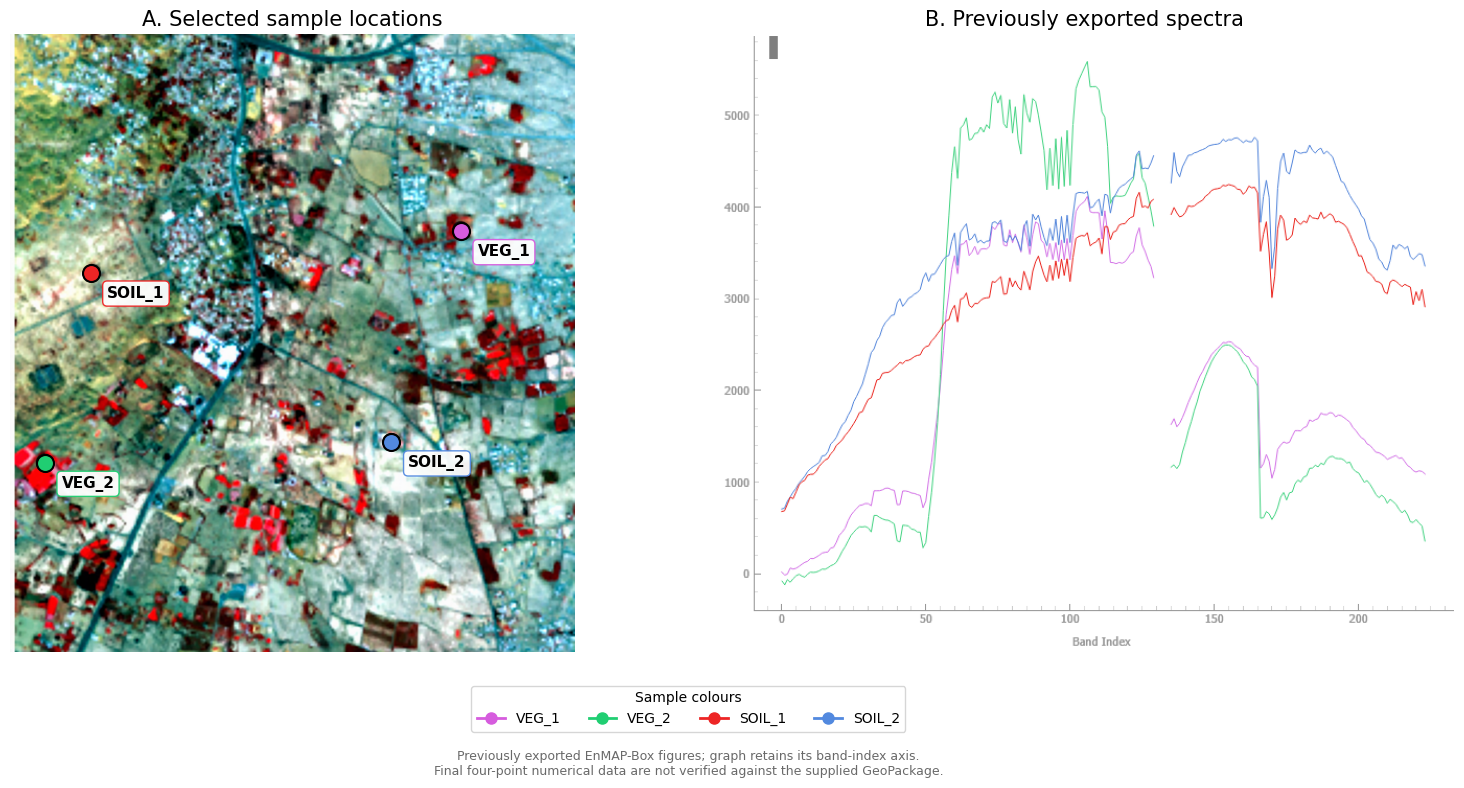

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

colours = {
    "VEG_1": "#d65cde",
    "VEG_2": "#20ce72",
    "SOIL_1": "#ed2525",
    "SOIL_2": "#5289df",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
map_ax, graph_ax = axes

map_ax.imshow(map_picture)
graph_ax.imshow(graph_picture)

map_ax.set_title("A. Selected sample locations", fontsize=15)
graph_ax.set_title("B. Previously exported spectra", fontsize=15)

# Relative positions in the supplied PNG, not geographic coordinates.
positions = {
    "VEG_1":  (0.798, 0.318),
    "VEG_2":  (0.061, 0.693),
    "SOIL_1": (0.142, 0.385),
    "SOIL_2": (0.675, 0.660),
}

width, height = map_picture.size

for name, (fx, fy) in positions.items():
    x, y = fx * width, fy * height

    map_ax.scatter(
        x, y, s=150, color=colours[name],
        edgecolor="black", linewidth=1.5, zorder=3
    )
    map_ax.annotate(
        name, (x, y),
        xytext=(12, -18), textcoords="offset points",
        fontsize=11, fontweight="bold",
        color="black",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white", edgecolor=colours[name],
            alpha=0.95
        )
    )

for ax in axes:
    ax.axis("off")

legend_items = [
    Line2D(
        [0], [0], color=colour, lw=2,
        marker="o", markersize=8, label=name
    )
    for name, colour in colours.items()
]

fig.legend(
    handles=legend_items,
    loc="lower center", bbox_to_anchor=(0.5, 0.07),
    ncol=4, frameon=True, title="Sample colours"
)

fig.text(
    0.5, 0.025,
    "Previously exported EnMAP-Box figures; graph retains its band-index axis.\n"
    "Final four-point numerical data are not verified against the supplied GeoPackage.",
    ha="center", fontsize=9, color="dimgray"
)

plt.tight_layout(rect=[0, 0.16, 1, 1])
fig.savefig("/content/RAK_four_samples_combined.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
files.download("/content/RAK_four_samples_combined.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

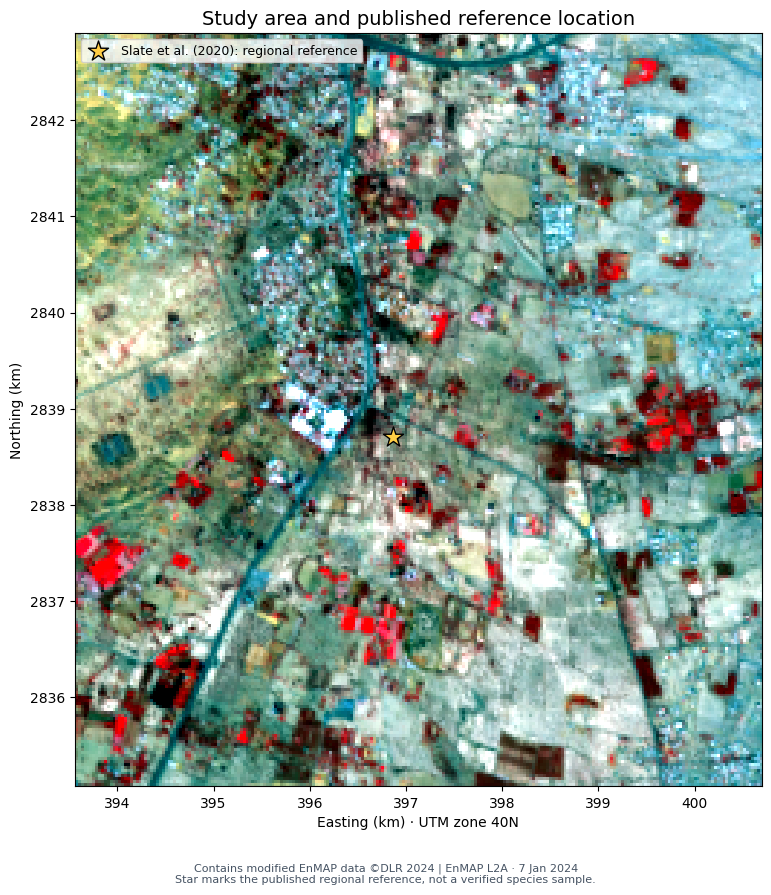

In [ ]:
fig, ax = plt.subplots(figsize=(8, 9))

ax.imshow(
    cir, extent=extent,
    origin="upper", interpolation="nearest"
)
map_axis(ax)

# Published regional reference location
lit_x, lit_y = lonlat_to_utm40(55.972372, 25.662480)

ax.scatter(
    lit_x / 1000, lit_y / 1000,
    marker="*", s=230,
    color="#ffce45", edgecolor="black",
    zorder=6,
    label="Slate et al. (2020): regional reference"
)

ax.set_title("Study area and published reference location")
ax.legend(loc="upper left", fontsize=9)

finish(
    fig,
    "study_area_reference.png",
    "Star marks the published regional reference, not a verified species sample."
)

## 9. Literature-informed wavelength relevance
[Howari et al. (2022), section 3.1 and Figure 4](https://pmc.ncbi.nlm.nih.gov/articles/PMC8912357/)
report field-spectrometer absorption features at 679, 1440, 1769 and 1938 nm (major) and
416, 503, 976 and 1171 nm (minor). The field spectra were recorded in Ajman on 22 February 2019
at close/far distances and decoded in ENVI. These are **field observations**, not EnMAP-trained
species features. The satellite component used historical Landsat imagery, not this EnMAP scene.

The table maps the six requested leads to this scene's band centres and FWHM. Nearest does not mean
usable: 1440 nm falls in a masked region; 1938 nm is not covered by a corresponding band; 976 nm
falls in the interleaved sensor region. No substitute at a distant wavelength is used as the missing feature.
The other features are candidates for future tests with confirmed references, not unique species identifiers.

[Slate et al. (2020)](https://doi.org/10.1007/s11258-020-01040-1) report co-occurring Prosopis species
at approximately 25.662480° N, 55.972372° E in a regional field study. The star on our map is only that
literature reference, not a verified tree or a 2024 pixel label. Their field dates differ from our satellite date.


In [ ]:
interpretations={679:'Candidate red absorption region; not species-specific',976:'Exclude: VNIR/SWIR overlap; not a robust stand-alone feature',
1171:'Candidate SWIR region; needs field/satellite spectral response matching',1440:'Exclude: water-absorption margin; no close valid proxy used',
1769:'Candidate near atmospheric-window edge; inspect quality carefully',1938:'Unavailable at target: band gap; do not substitute 1967.66 nm'}
literature_rows=[]
for target,note in interpretations.items():
    j=int(np.argmin(abs(wavelengths-target)))
    literature_rows.append({'reported_feature_nm':target,'nearest_band':j+1,'band_centre_nm':float(wavelengths[j]),
       'difference_nm':float(abs(wavelengths[j]-target)),'FWHM_nm':float(fwhm[j]),
       'excluded_from_main_plot':bool(plot_excluded[j]),'interpretation':note})
save_csv('literature_wavelengths.csv',literature_rows)
show_table(literature_rows)


reported_feature_nm,nearest_band,band_centre_nm,difference_nm,FWHM_nm,excluded_from_main_plot,interpretation
679,50,679.691000,0.691000,7.826700,False,Candidate red absorption region; not species-specific
976,97,977.037000,1.037000,10.753300,True,Exclude: VNIR/SWIR overlap; not a robust stand-alone feature
1171,117,1175.310000,4.310000,11.365600,False,Candidate SWIR region; needs field/satellite spectral response matching
1440,136,1449.430000,9.430000,11.122000,True,Exclude: water-absorption margin; no close valid proxy used
1769,165,1769.890000,0.890000,9.875640,False,Candidate near atmospheric-window edge; inspect quality carefully
1938,167,1967.660000,29.660000,9.046940,True,Unavailable at target: band gap; do not substitute 1967.66 nm


## 10. Results and observations
The following summary is generated from the actual run. Index differences and visible red-edge rises
support an exploratory vegetation-like versus soil-like comparison. They do not establish species or
independent classification accuracy. Both soil records are counted once when discussing unique locations.
A full raster grid includes roads, built areas and other surfaces; its mean NDVI is not a mean plant-health score.


In [ ]:
summary={'dataset':'EnMAP RAK 2024-01-07; original supplied clip','total_pixels':qa['total_pixels'],
 'any_band_valid_pixels':qa['any_band_valid_pixels'],'all_nodata_bands':nodata_bands.tolist(),
 'index_statistics':index_stats,'sample_records':len(samples),'unique_sample_locations':unique_count,
 'final_four_samples_verified':bool(final_names_verified),'species_confirmed':False,
 'sample_indices':[{k:v for k,v in r.items() if k in ('original_name','NDVI','NDRE','duplicate_of')} for r in sample_rows]}
(OUT/'results_summary.json').write_text(json.dumps(summary,indent=2))
print(f"Grid: {qa['total_pixels']:,} pixels; {len(nodata_bands)} entirely missing bands.")
for s in index_stats:print(f"{s['index']}: n={s['valid_pixels']:,}; mean={s['mean']:.4f}; median={s['median']:.4f}; range {s['minimum']:.4f} to {s['maximum']:.4f}")
for p in sample_rows:print(f"{p['original_name']}: NDVI={p['NDVI']:.4f}, NDRE={p['NDRE']:.4f}")
print('Confirmed species labels: 0. Distinct georeferenced sampled pixels:',unique_count)


Grid: 62,118 pixels; 5 entirely missing bands.
NDVI: n=62,118; mean=0.1508; median=0.1192; range -0.0377 to 0.8833
NDRE: n=62,118; mean=0.1025; median=0.0781; range -0.0345 to 0.7173
Sample_01: NDVI=0.5423, NDRE=0.3515
Sample_02: NDVI=0.4789, NDRE=0.3293
Soil_Candidate_01: NDVI=0.1194, NDRE=0.0764
Soil_Candidate_02: NDVI=0.1194, NDRE=0.0764
Confirmed species labels: 0. Distinct georeferenced sampled pixels: 3


## 11. Limitations and scope of this initial study

This project began with the intention of using Planet Tanager hyperspectral imagery. Limitations in the Tanager data available to the team led us to use EnMAP imagery for this initial investigation. The resulting workflow demonstrates image preparation, vegetation-index mapping and exploratory spectral comparison, providing a foundation for further research into invasive Mesquite (*Prosopis juliflora*).

The current study has several limitations:

- **Species identification:** No field-confirmed species samples were available for validation. Vegetation indices and visually selected spectra therefore cannot confirm Mesquite presence or distinguish it reliably from Ghaf and other vegetation.
- **Spatial and temporal coverage:** The analysis uses one EnMAP acquisition, dated 7 January 2024. Its 30 m pixels can contain mixtures of vegetation, soil and shadow. The study does not measure individual trees, invasion rates or changes over time.
- **Sample-data completeness:** The four final selections are presented as previously exported images. Their numerical spectra and coordinates are not preserved in the supplied GeoPackage, which contains an earlier sample set with a duplicate soil record. The final four-sample comparison cannot currently be reproduced from that file.
- **Image quality:** Missing bands, atmospheric effects and the absence of clip-specific cloud and shadow masks limit spectral interpretation.
- **Reproducibility:** Rerunning the analysis requires the matching input files and a compatible environment. The current data readers were designed for the supplied dataset.

These limitations define the next research steps. The present results support exploratory vegetation assessment; species-level detection remains a future objective.

## 12. Further research and development

1. Recover or re-export the four final samples with their names, coordinates and numerical spectra, then check them against the source raster.
2. Collect field-confirmed samples of Mesquite, Ghaf, other vegetation and bare soil, recording location and canopy conditions based on more studies and obtain data from official agency.
3. Expand the spectral reference library and investigate which features consistently distinguish Mesquite from similar vegetation.
4. Obtain suitable additional EnMAP or Tanager imagery, where available, together with quality masks and multiple acquisition dates.
5. Develop and test classification methods using independent validation sites, reporting accuracy and uncertainty.
6. Investigate vegetation change over time and verify suspected changes through field observations.
7. Produce candidate-area maps that environmental and agricultural teams can use to prioritize field inspection.

## 13. Conclusion

This project establishes an initial EnMAP-based workflow for exploring vegetation patterns and spectral differences in the study area. It combines satellite-derived image composites and vegetation indices with previously exported sample figures and a published regional reference location.

The work provides a starting point for research into invasive Mesquite rather than a validated species-detection system. With complete sample records, field observations and additional imagery, future development could evaluate its usefulness for identifying candidate Mesquite locations and supporting monitoring and management.

- Howari, F. M., et al. (2022). *Changes in the Invasion Rate of Prosopis juliflora and Its Impact on
  Depletion of Groundwater in the Northern Part of the United Arab Emirates.* Plants 11(5), 682.
  [DOI](https://doi.org/10.3390/plants11050682). Spectral evidence: §3.1, Fig. 4.
- Slate, M. L., et al. (2020). *Exotic Prosopis juliflora suppresses understory diversity and promotes
  agricultural weeds more than a native congener.* [DOI](https://doi.org/10.1007/s11258-020-01040-1).
  [Author copy](https://par.nsf.gov/servlets/purl/10158886). Regional field context only.
- DLR EnMAP [FAQ v2.7, 30 April 2026](https://www.enmap.org/data/doc/EnMAP_FAQ.pdf), §§5.1–5.5, 5.12.
- DLR [Data and Access](https://www.enmap.org/data_access/) and
  [EnMAP Data Licence v1.1](https://www.enmap.org/data/resources/EnMAP_Data_License.pdf).
- Snyder (1987), *Map Projections—A Working Manual*, USGS Professional Paper 1395,
  Transverse Mercator equations. [DOI](https://doi.org/10.3133/pp1395).
- Source-data DOI, from the supplied XML: [10.15489/rlyibn8gjc58](https://doi.org/10.15489/rlyibn8gjc58),
  DLR (2026), EnMAP L0 source processed to L2A version 010502, parameters U0BLNNTS297G.

Source EnMAP data ©DLR 2024 All rights reserved. Figures contain modified EnMAP data ©DLR 2024.


### Execution checks
These are engineering/data checks, not ecological validation metrics. The expected final-sample
failure is reported explicitly while the supported analysis completes. Notebook outputs are saved by
`scripts/run_notebook.py`; the same mandatory cells contain ordinary Python usable in Jupyter/Colab.


In [ ]:
expected_figures=['true_color.png','color_infrared.png','ndvi.png','ndre.png','spectral_profiles.png','sampling_locations.png']
assert all((OUT/n).stat().st_size>1000 for n in expected_figures)
assert all(r['profile_matches_raster'] for r in sample_rows)
assert np.allclose(gain,.0001) and np.allclose(offset,0)
checks={'Original EnMAP raster opened':'Pass','XML wavelengths mapped':'Pass','Reflectance scaling verified':'Pass',
 'True-color image generated':'Pass','CIR image generated':'Pass','NDVI computed':'Pass','NDRE computed':'Pass',
 'Four final sampling points verified':'Pass' if final_names_verified else 'Fail: four earlier records; three unique locations',
 'Spectral comparison generated':'Pass: original names; duplicate marked',
 'Species classification':'Not attempted; no ground truth',
 'Actual Google Colab runtime':'Not tested','Public unattended data retrieval':'Not verified; licence/access blocker'}
(OUT/'analysis_checks.json').write_text(json.dumps(checks,indent=2))
for k,v in checks.items():print(k+': '+v)


Original EnMAP raster opened: Pass
XML wavelengths mapped: Pass
Reflectance scaling verified: Pass
True-color image generated: Pass
CIR image generated: Pass
NDVI computed: Pass
NDRE computed: Pass
Four final sampling points verified: Fail: four earlier records; three unique locations
Spectral comparison generated: Pass: original names; duplicate marked
Species classification: Not attempted; no ground truth
Actual Google Colab runtime: Not tested
Public unattended data retrieval: Not verified; licence/access blocker


## Saved results for review
These figures come from the earlier analysis and exported sample images. They can be viewed without rerunning the notebook. Recalculation requires the original input files.

### True-colour map

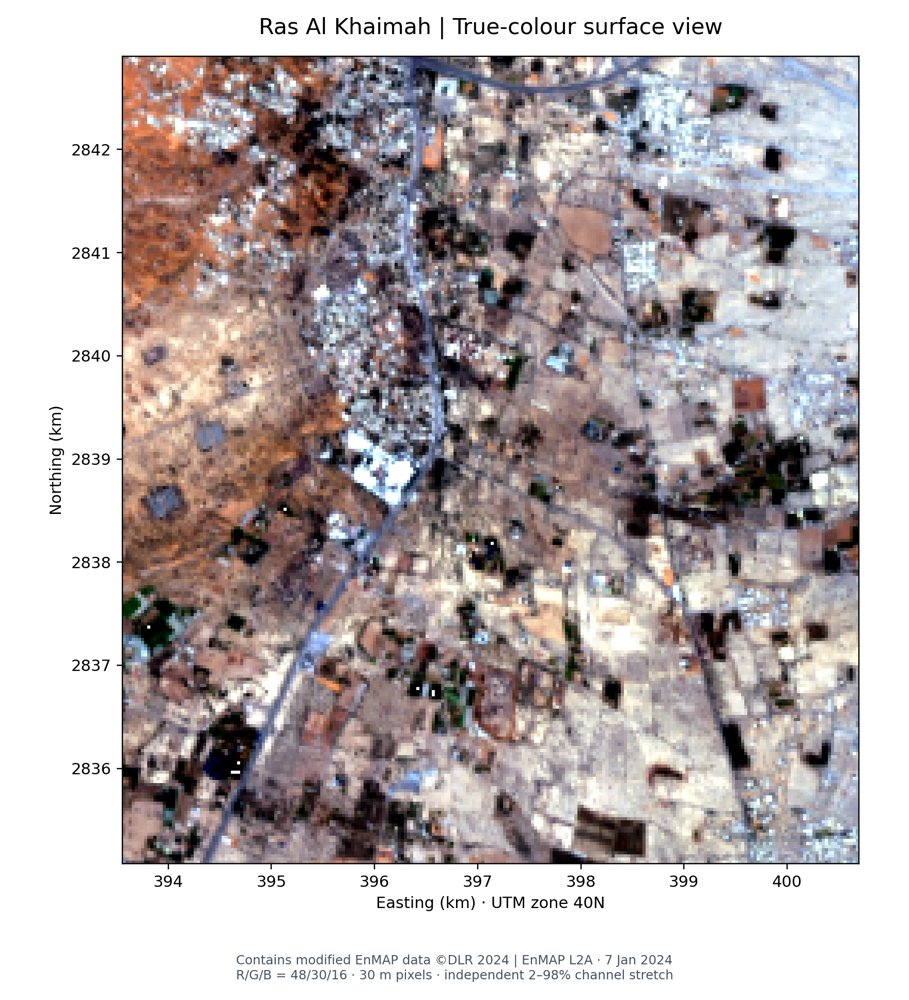

### Colour-infrared map

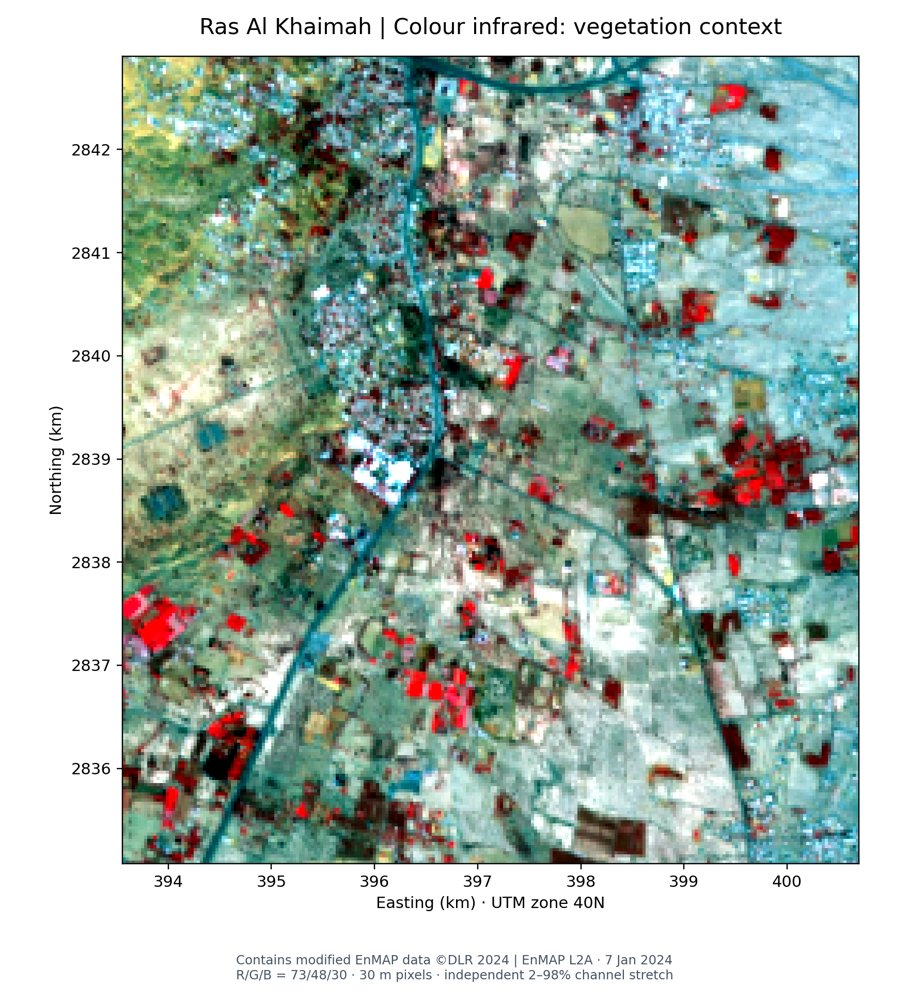

### NDVI

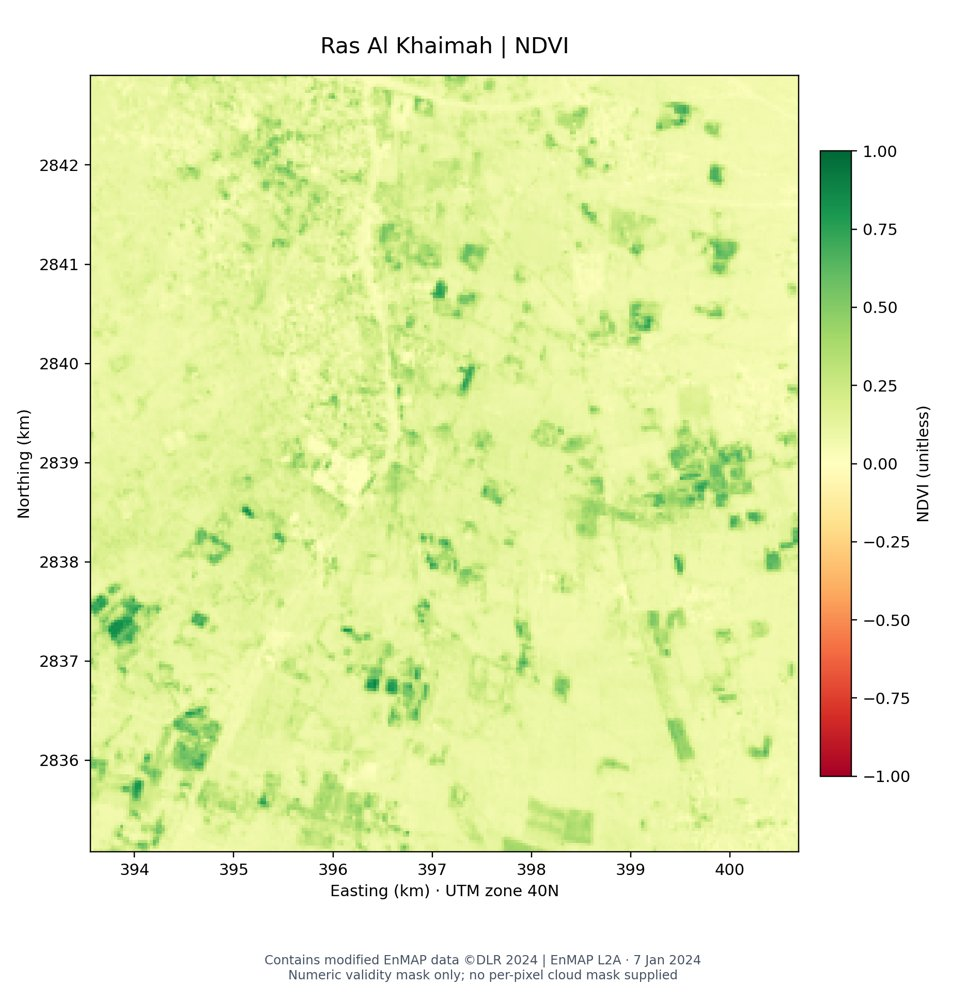

### NDRE

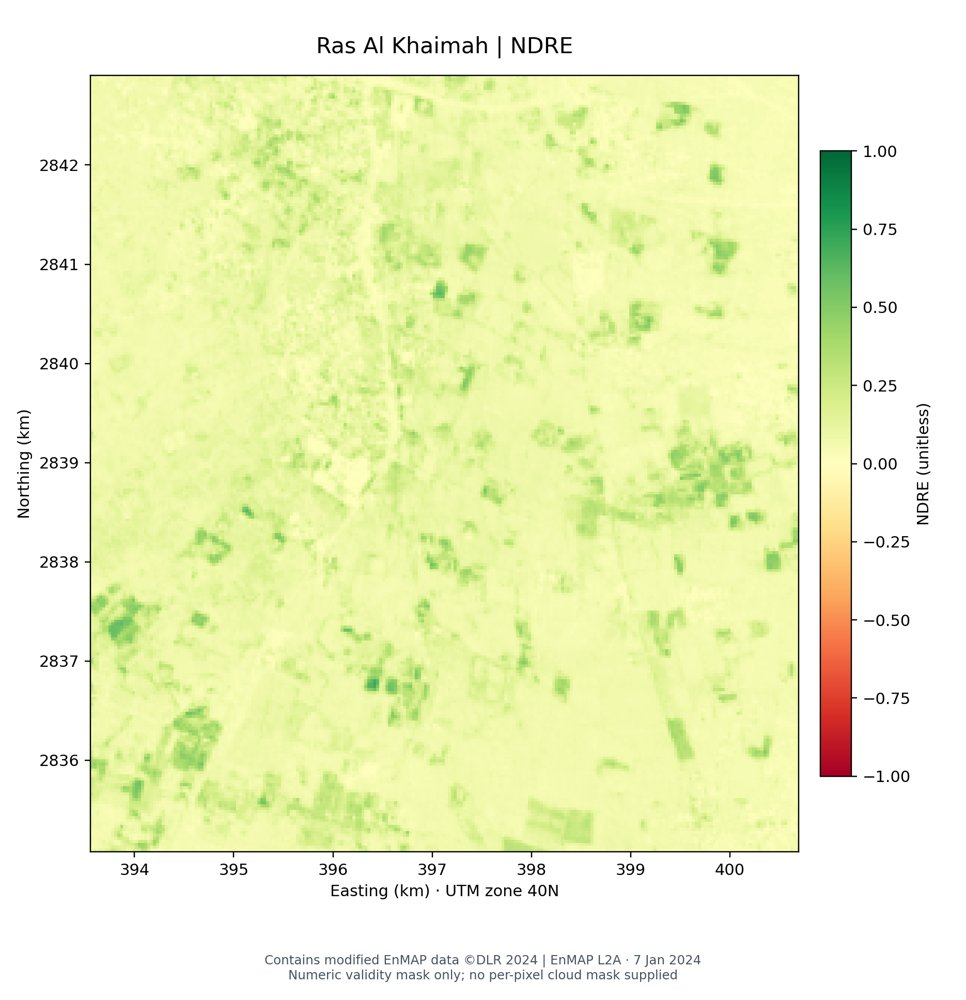

### Four exported samples

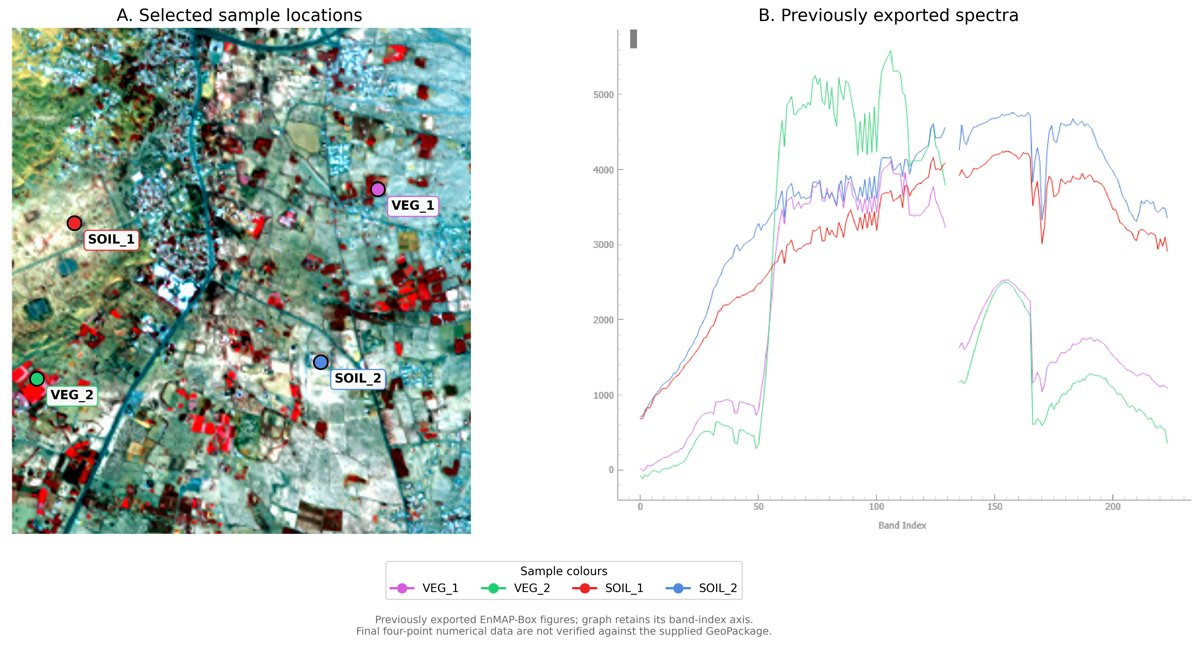

### Study area and reference star

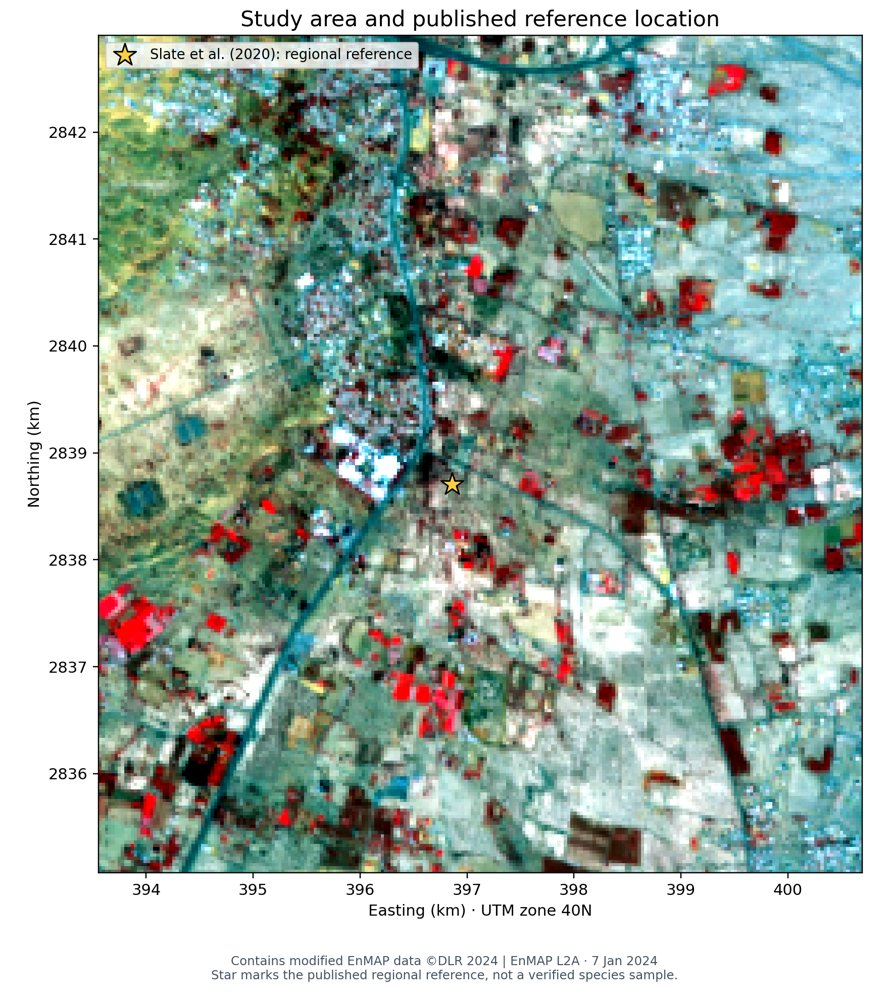

In [ ]:
from pathlib import Path
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import display, Image, Markdown

folders = [Path("/content"), Path("/content/outputs")]
if "OUT" in globals():
    folders.insert(0, Path(OUT))

figures = [
    ("True-colour map", "true_color.png"),
    ("Colour-infrared map", "color_infrared.png"),
    ("NDVI", "ndvi.png"),
    ("NDRE", "ndre.png"),
    ("Four exported samples", "RAK_four_samples_combined.png"),
    ("Study area and reference star", "study_area_reference.png"),
]

display(Markdown(
    "## Saved results for review\n"
    "These figures come from the earlier analysis and exported "
    "sample images. They can be viewed without rerunning the notebook. "
    "Recalculation requires the original input files."
))

for title, filename in figures:
    path = next(
        (folder / filename for folder in folders
         if (folder / filename).is_file()),
        None
    )
    if path is None:
        print(f"Not found in this session: {filename}")
        continue

    with PILImage.open(path) as picture:
        picture = picture.convert("RGB")
        picture.thumbnail((1200, 1000))
        buffer = BytesIO()
        picture.save(buffer, format="JPEG", quality=85)

    display(Markdown(f"### {title}"))
    display(Image(data=buffer.getvalue(), format="jpeg"))